# Task 3 — Spending persistence and lapse EDA

One linear notebook creates exactly one dataset, `eda_spend_persistence_v2`, from raw competition Train/Test. It reproduces the 16 prior row-wise features and adds eight deterministic candidates prompted by the OOF finding that large prior spending can yield costly false-nonzero predictions. Test is used only for schema checks and the same row-wise transformations. No target-derived statistics or fitted preprocessing enter saved features.

In [1]:
from pathlib import Path
import json,sys
ROOT=next(p for p in (Path.cwd(),*Path.cwd().parents)
          if (p/"src"/"pipeline"/"save_data.py").exists())
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
from src.pipeline.random_seed import set_seed
from src.pipeline.save_data import save_data
SEED=set_seed()
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.model_selection import train_test_split,StratifiedKFold
sns.set_theme(style="whitegrid")
SRC=ROOT/"src"
TASK=SRC/"task3"
RAW=TASK/"data"/"raw"
TARGET,ID="spending_30d","player_id"
DATA_NAME="eda_spend_persistence_v2"
train_raw=pd.read_csv(RAW/"train.csv")
test_raw=pd.read_csv(RAW/"test.csv")
assert TARGET in train_raw and TARGET not in test_raw
assert train_raw.columns.drop(TARGET).tolist()==test_raw.columns.tolist()
assert train_raw[ID].is_unique and test_raw[ID].is_unique
assert not set(train_raw[ID]) & set(test_raw[ID])
feature_cols=test_raw.columns.drop(ID).tolist()
assert len(feature_cols)==32 and train_raw[TARGET].notna().all()
assert (train_raw[TARGET]>=0).all()
assert all(pd.api.types.is_numeric_dtype(train_raw[c]) for c in feature_cols)
print("Raw Train/Test rows:",len(train_raw),len(test_raw),"predictors:",len(feature_cols))
display(train_raw[TARGET].describe(percentiles=[.5,.9,.95,.99]).to_frame())

Raw Train/Test rows: 104000 25889 predictors: 32


,spending_30d
count,104000.000000
mean,10497.040585
std,30568.961446
min,0.000000
50%,79.435000
90%,37718.851000
95%,75969.751000
99%,150032.295400
max,300000.000000


## 1. Explore high prior spending and lapse signals

Reconstruct the existing OOF gate decision with its saved threshold and exact development split. Within the highest prior-spending quintile, inspect actual zero rates and false-nonzero cost by purchase recency and frequency. These bins are only descriptive; none becomes a saved feature.

Prior-spend top-quintile cutoff: 1823.45 rows: 15673
Zero target rate: 0.133 false-nonzero rate: 0.133


days_since_last_purchase


,rows,zero_rate,false_nonzero_rate,false_nonzero_cost
bin,,,,
"(-0.0005070000000000001, 11.319]",3690,0.104,0.104,1.463954e+07
"(11.319, 23.459]",3690,0.115,0.115,1.402241e+07
"(23.459, 38.459]",3690,0.142,0.142,1.576859e+07
"(38.459, 116.724]",3690,0.176,0.176,1.112800e+07
Missing,913,0.112,0.112,2.236927e+06


purchase_frequency


,rows,zero_rate,false_nonzero_rate,false_nonzero_cost
bin,,,,
"(0.9999999999999999, 7.056]",3685,0.161,0.161,1.188045e+07
"(11.095, 14.625]",3684,0.121,0.121,1.246027e+07
"(14.625, 25.0]",3685,0.108,0.108,1.484138e+07
"(7.056, 11.095]",3685,0.144,0.144,1.582125e+07
Missing,934,0.126,0.126,2.792121e+06


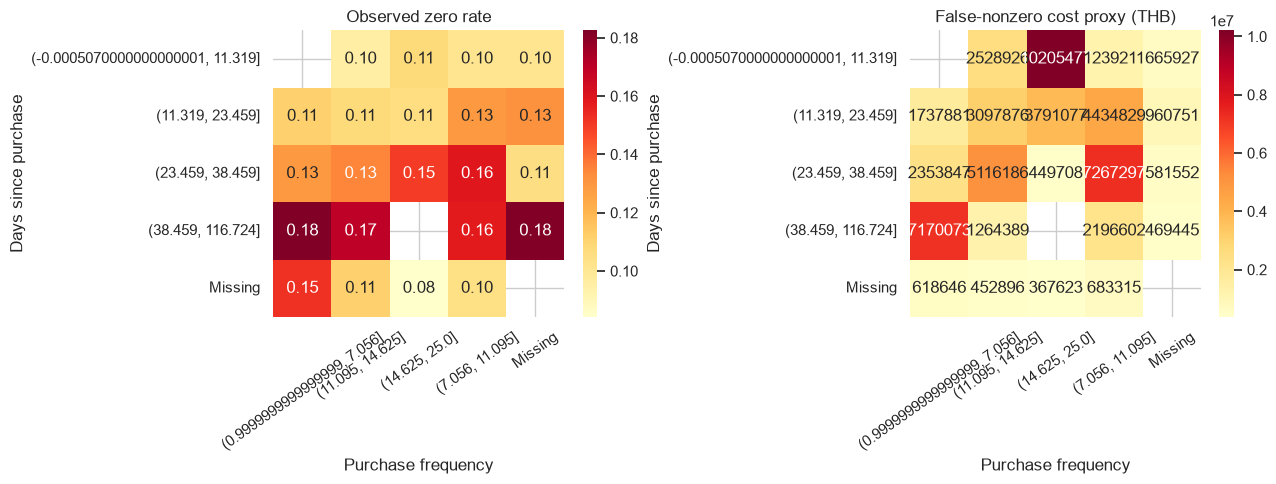

In [2]:
old_card=json.loads((TASK/"data"/"eda"/"eda_combined_v1.json").read_text(encoding="utf-8"))
old_train=pd.read_parquet(SRC/old_card["splits"]["train"]["path"])
assert old_train[ID].equals(train_raw[ID]) and old_train[TARGET].equals(train_raw[TARGET])
y=train_raw[TARGET].astype(float)
bands=pd.cut(y,bins=[-1,0,100,1000,10000,50000,np.inf],labels=False)
dev_idx,_=train_test_split(np.arange(len(y)),test_size=.20,stratify=bands,random_state=SEED)
dev=train_raw.iloc[dev_idx].reset_index(drop=True)
dev_bands=bands.iloc[dev_idx].reset_index(drop=True)
splits=list(StratifiedKFold(n_splits=5,shuffle=True,random_state=SEED).split(dev,dev_bands))
threshold=float(json.loads((TASK/"save"/"t3_positive_gate_cv5_v2.json").read_text(encoding="utf-8"))["card"]["threshold"])
parts=[]
for fold,(_,check_pos) in enumerate(splits,1):
    part=pd.read_parquet(TASK/"models"/"results"/f"round3_gate_fold{fold}_v1.parquet")
    assert part.row_pos.tolist()==check_pos.tolist()
    parts.append(part)
gate_oof=pd.concat(parts,ignore_index=True).sort_values("row_pos").reset_index(drop=True)
assert gate_oof.row_pos.tolist()==list(range(len(dev)))
assert np.array_equal(gate_oof.true,dev[TARGET])
audit=dev[[TARGET,"prev_month_spending","historical_spending",
           "days_since_last_purchase","purchase_frequency","total_transactions"]].copy()
audit["false_nonzero"]=(audit[TARGET]==0)&(gate_oof.probability>=threshold)
audit["false_nonzero_cost_proxy"]=np.where(audit.false_nonzero,np.maximum(gate_oof.positive_amount,0),0)
q80=audit.prev_month_spending.quantile(.8)
high_prev=audit.loc[audit.prev_month_spending>=q80].copy()
print("Prior-spend top-quintile cutoff:",round(q80,2),"rows:",len(high_prev))
print("Zero target rate:",round((high_prev[TARGET]==0).mean(),3),
      "false-nonzero rate:",round(high_prev.false_nonzero.mean(),3))
for feature in ["days_since_last_purchase","purchase_frequency"]:
    bins=pd.qcut(high_prev[feature],q=4,duplicates="drop").astype("string").fillna("Missing")
    table=(high_prev.assign(bin=bins).groupby("bin")
        .agg(rows=(TARGET,"size"),zero_rate=(TARGET,lambda x:(x==0).mean()),
             false_nonzero_rate=("false_nonzero","mean"),
             false_nonzero_cost=("false_nonzero_cost_proxy","sum")))
    print(feature);display(table.round(3))
recency_bin=pd.qcut(high_prev.days_since_last_purchase,q=4,duplicates="drop").astype("string").fillna("Missing")
frequency_bin=pd.qcut(high_prev.purchase_frequency,q=4,duplicates="drop").astype("string").fillna("Missing")
heat=(high_prev.assign(recency_bin=recency_bin,frequency_bin=frequency_bin)
      .groupby(["recency_bin","frequency_bin"])
      .agg(rows=(TARGET,"size"),zero_rate=(TARGET,lambda x:(x==0).mean()),
           false_nonzero_cost=("false_nonzero_cost_proxy","sum")).reset_index())
fig,axes=plt.subplots(1,2,figsize=(13,5))
for ax,value,title in zip(axes,["zero_rate","false_nonzero_cost"],
                          ["Observed zero rate","False-nonzero cost proxy (THB)"]):
    table=heat.pivot(index="recency_bin",columns="frequency_bin",values=value)
    count=heat.pivot(index="recency_bin",columns="frequency_bin",values="rows").reindex_like(table)
    sns.heatmap(table.where(count>=100),annot=True,fmt=".2f" if value=="zero_rate" else ".0f",
                cmap="YlOrRd",ax=ax)
    ax.set(title=title,xlabel="Purchase frequency",ylabel="Days since purchase")
    ax.tick_params(axis="x",labelrotation=35)
plt.tight_layout();plt.show()

## 2. Reproduce prior features and add eight candidates

The prior formulas are copied into this notebook, so it does not import or execute another notebook at runtime. The old saved dataset is read only to verify equivalence. The new **persistence** and **tail** families use row-wise values, propagate missing inputs, and contain no target or ID.

In [3]:
def add_spending_features(df):
    out = df.copy()
    out["purchase_value_proxy"] = df["purchase_frequency"] * df["avg_transaction_value"]
    out["recent_to_historical_spend"] = df["prev_month_spending"] / (df["historical_spending"] + 1)
    out["historical_spend_per_account_month"] = df["historical_spending"] / (df["account_age_days"] / 30 + 1)
    out["transactions_per_account_month"] = df["total_transactions"] / (df["account_age_days"] / 30 + 1)
    out["historical_spend_per_transaction"] = df["historical_spending"] / (df["total_transactions"] + 1)
    out["discount_purchase_share"] = df["purchases_on_discount"] / (df["total_transactions"] + 1)
    out["discount_value_interaction"] = df["prev_month_spending"] * df["discount_rate_used"]
    out["purchase_recency_over_age"] = df["days_since_last_purchase"] / (df["account_age_days"] + 1)
    out["login_purchase_recency_gap"] = df["days_since_last_purchase"] - df["days_since_last_login"]
    out["session_hours_proxy_per_week"] = df["sessions_per_week"] * df["avg_session_length"] / 60
    out["play_hours_per_account_day"] = df["total_playtime_hours"] / (df["account_age_days"] + 1)
    out["social_interactions_per_session"] = df["social_interactions"] / (df["sessions_per_week"] + 1)
    out["cross_game_activity_per_session"] = df["cross_game_activity"] / (df["sessions_per_week"] + 1)
    out["achievements_per_play_hour"] = df["achievement_count"] / (df["total_playtime_hours"] + 1)
    out["event_social_interaction"] = df["event_participation_rate"] / 100 * df["social_interactions"]
    out["source_missing_count"] = df[feature_cols].isna().sum(axis=1)
    return out

train_prior=add_spending_features(train_raw)
test_prior=add_spending_features(test_raw)
assert train_prior.columns.tolist()==old_train.columns.tolist()
assert train_prior[ID].equals(old_train[ID])
assert all(np.allclose(train_prior[c].to_numpy(dtype=float),old_train[c].to_numpy(dtype=float),
                       equal_nan=True,rtol=1e-10,atol=1e-10)
           for c in train_prior if c!=ID)
assert train_prior.drop(columns=TARGET).columns.tolist()==test_prior.columns.tolist()
print("Reproduced all 16 prior features exactly")

Reproduced all 16 prior features exactly


In [4]:
PERSISTENCE=["recent_spend_per_transaction","spend_persistence_proxy",
             "prior_spend_staleness","purchase_frequency_per_recency"]
TAIL=["historical_prev_spend_gap","prior_spend_per_account_month",
      "discounted_prev_spend_proxy","prev_spend_login_recency"]
def add_candidates(df):
    out=add_spending_features(df)
    out["recent_spend_per_transaction"]=df.prev_month_spending/(df.total_transactions+1)
    out["spend_persistence_proxy"]=df.prev_month_spending*df.purchase_frequency/(df.days_since_last_purchase+1)
    out["prior_spend_staleness"]=df.prev_month_spending*df.days_since_last_purchase/(df.account_age_days+30)
    out["purchase_frequency_per_recency"]=df.purchase_frequency/(df.days_since_last_purchase+1)
    out["historical_prev_spend_gap"]=df.historical_spending-df.prev_month_spending
    out["prior_spend_per_account_month"]=df.prev_month_spending/(df.account_age_days/30+1)
    out["discounted_prev_spend_proxy"]=df.prev_month_spending*out.discount_purchase_share
    out["prev_spend_login_recency"]=df.prev_month_spending/(df.days_since_last_login+1)
    return out
train_new=add_candidates(train_raw)
test_new=add_candidates(test_raw)
assert train_new[train_prior.columns].equals(train_prior)
assert test_new[test_prior.columns].equals(test_prior)
assert train_new.drop(columns=TARGET).columns.tolist()==test_new.columns.tolist()
assert len(PERSISTENCE+TAIL)==8 and len(test_new.columns)==1+32+16+8
assert not np.isinf(train_new[PERSISTENCE+TAIL].to_numpy()).any()
assert not np.isinf(test_new[PERSISTENCE+TAIL].to_numpy()).any()
display(pd.DataFrame({"missing_pct":train_new[PERSISTENCE+TAIL].isna().mean()*100,
                      "median":train_new[PERSISTENCE+TAIL].median(),
                      "p99":train_new[PERSISTENCE+TAIL].quantile(.99)}).round(2))

,missing_pct,median,p99
recent_spend_per_transaction,11.28,18.15,771.11
spend_persistence_proxy,16.54,181.14,64153.25
prior_spend_staleness,16.52,26.48,2771.75
purchase_frequency_per_recency,11.41,0.32,10.79
historical_prev_spend_gap,11.23,1032.99,49508.09
prior_spend_per_account_month,11.27,30.92,3104.93
discounted_prev_spend_proxy,16.49,182.78,11140.01
prev_spend_login_recency,11.26,84.58,8405.00


## 3. Save exactly one dataset

The primary JSON card lists the train/test files and both candidate families. Rerunning checks the existing artifact instead of overwriting it.

In [5]:
card_path=TASK/"data"/"eda"/f"{DATA_NAME}.json"
if card_path.exists():
    existing=json.loads(card_path.read_text(encoding="utf-8"))
    assert existing["card"]["feature_notebook"]=="task3/eda/build_eda_2.ipynb"
    assert list(existing["splits"]["train"]["columns"])==train_new.columns.tolist()
    assert list(existing["splits"]["test"]["columns"])==test_new.columns.tolist()
    print("Loaded existing dataset card:",card_path)
else:
    result=save_data(task=3,name=DATA_NAME,train=train_new,test=test_new,
        format="parquet",card={
            "source":"task3/data/raw/train.csv and test.csv",
            "preparation":"Reproduced 16 prior deterministic row-wise features and added eight persistence/lapse candidates; no fitted transforms, imputation, target statistics, or Test analysis.",
            "feature_notebook":"task3/eda/build_eda_2.ipynb",
            "candidate_groups":{"persistence":PERSISTENCE,"tail":TAIL},
            "leakage_review":"Timing of historical_spending, prev_month_spending, segment, and VIP fields remains unverified; no target or ID in formulas.",
            "metric_note":"MAE THB only; official NMAE denominator unavailable"})
    print(result["splits"]["train"]["path"],result["splits"]["test"]["path"])

task3/data/eda/eda_spend_persistence_v2-train.parquet task3/data/eda/eda_spend_persistence_v2-test.parquet
